# Head-up displays: the windshield as an off-axis mirror

A head-up display (HUD) shows speed, navigation arrows and warnings as a
virtual image floating in front of the car, so the driver does not have
to look down and refocus. A picture generating unit (PGU, an LCD or a
laser scanner) in the dashboard is imaged by one or two mirrors and the
**windshield** itself, which reflects a few per cent of the light into the
driver's eyes. The windshield is the last and most awkward element of the
system: a tilted, curved, two-sided piece of laminated glass that the
optical designer does not get to choose. Conventional HUDs put the image
2 to 3 m ahead; **AR-HUDs**, which paint arrows onto the road, need 7 to
15 m and a larger field.

This notebook builds a HUD from the pieces of earlier notebooks: Fresnel
reflection (notebook 10, interfaces and thin films),
a thin film coating (notebook 12, layer stacks), the ray
tracer with tilted mirrors and freeform Zernike surfaces
(notebook 19, ray tracing to OPD), and the off-axis astigmatism of
the Czerny–Turner in
notebook 110 (grating and prism spectrometers).
The sections are:

1. the windshield as a mirror: reflectance, polarization and polarized
   sunglasses,
2. the double image of the two surfaces and the wedged interlayer,
3. the ray traced HUD: virtual image distance and astigmatism of an
   off-axis spherical mirror,
4. a freeform mirror that corrects the windshield,
5. what the two eyes see: disparity, and distortion across the eye box.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

from pyoptics import arvr
from pyoptics import interfaces as itf
from pyoptics import thin_films as tf
from pyoptics import sketch

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
ARCMIN = np.pi/180/60
t_start = time.time()

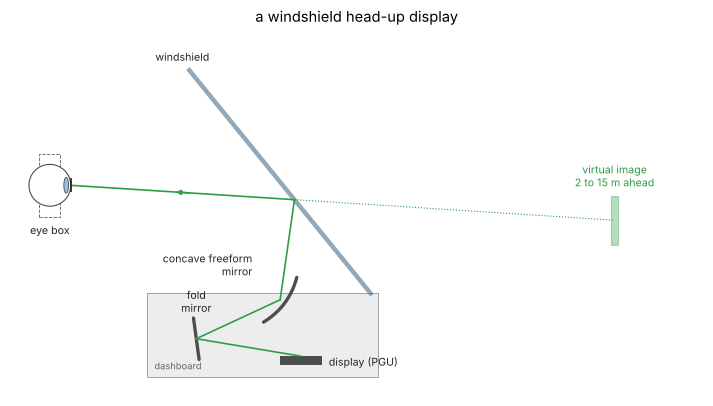

In [2]:
fig, ax = plt.subplots(figsize=(12, 6))
with sketch.text_scale(1.2):
    sketch.hud_layout(ax, "layout", title="a windshield head-up display")
plt.show()

## 1. The windshield as a mirror

Windshields are raked: the driver looks through them at 60° to 65° from
the normal. Close to the Brewster angle of glass (56.7° for $n = 1.52$),
the reflectance depends strongly on the polarization: s light (electric
field along the windshield, horizontal) is reflected by about 20 %,
p light (in the plane of incidence) by well under 1 %. Conventional HUDs
therefore send s-polarized light, and an LCD-based PGU emits polarized
light anyway.

The catch: **polarized sunglasses** block horizontal polarization (the glare
from the road and from the windshield's dashboard reflection), which is
exactly the s-polarized HUD image. A HUD with p-polarized light survives
sunglasses, but needs the windshield to reflect p, for example with a
high-index coating on the inner surface. Below the bare glass, and one
TiO₂ layer ($n = 2.4$) as the simplest such coating, computed with
`thin_films`. The second surface of the windshield (glass to air,
seen from inside) reflects as much as the first for bare glass; it is the
source of the double image of section 2.

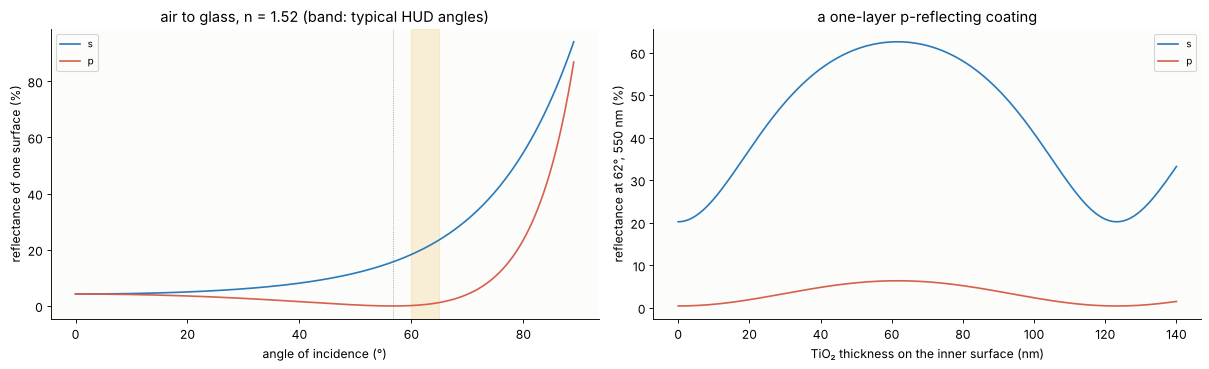

bare glass at 62°: R_s = 20.2%, R_p = 0.43%; Brewster angle 56.7°
TiO2 62 nm: R_p = 6.4%, R_s = 62.6%; transmission of unpolarized light at 62° through this surface 66% (bare 90%)
s: ghost / image = 0.64 (bare glass, second surface through the first twice)
p: ghost / image = 0.99 (bare glass, second surface through the first twice)


In [3]:
N_GLASS = 1.52
TH_W = np.radians(62.0)
ang = np.radians(np.linspace(0, 89, 360))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), layout="constrained")
axs[0].plot(np.degrees(ang), 100*itf.R_s(ang, 1.0, N_GLASS), color=BLUE, label="s")
axs[0].plot(np.degrees(ang), 100*itf.R_p(ang, 1.0, N_GLASS), color=RED, label="p")
axs[0].axvline(np.degrees(itf.brewster_angle(1.0, N_GLASS)), color=GREY, lw=0.6, ls=":")
axs[0].axvspan(60, 65, color=ORANGE, alpha=0.15)
axs[0].set_xlabel("angle of incidence (°)")
axs[0].set_ylabel("reflectance of one surface (%)")
axs[0].set_title("air to glass, n = 1.52 (band: typical HUD angles)")
axs[0].legend(fontsize=9)
t_tio2 = np.linspace(0, 140, 141)
Rc = {pol: np.array([tf.R_T_A_coeffs(TH_W, np.array([2.4]), np.array([0.0]), np.array([t]), 1.0, 0.0,
                                     N_GLASS, 0.0, pol, 550.0)[0] for t in t_tio2]) for pol in ("s", "p")}
axs[1].plot(t_tio2, 100*Rc["s"], color=BLUE, label="s")
axs[1].plot(t_tio2, 100*Rc["p"], color=RED, label="p")
axs[1].set_xlabel("TiO₂ thickness on the inner surface (nm)")
axs[1].set_ylabel("reflectance at 62°, 550 nm (%)")
axs[1].set_title("a one-layer p-reflecting coating")
axs[1].legend(fontsize=9)
plt.show()
Rs0, Rp0 = itf.R_s(TH_W, 1.0, N_GLASS), itf.R_p(TH_W, 1.0, N_GLASS)
i_best = np.argmax(Rc["p"])
print("bare glass at 62°: R_s = {:.1%}, R_p = {:.2%}; Brewster angle {:.1f}°".format(
    Rs0, Rp0, np.degrees(itf.brewster_angle(1.0, N_GLASS))))
print("TiO2 {:.0f} nm: R_p = {:.1%}, R_s = {:.1%}; transmission of unpolarized light at 62° "
      "through this surface {:.0%} (bare {:.0%})".format(
          t_tio2[i_best], Rc["p"][i_best], Rc["s"][i_best], 1 - (Rc["s"][i_best] + Rc["p"][i_best])/2,
          1 - (Rs0 + Rp0)/2))
# second surface (glass -> air inside the windshield) relative to the first, for s and p
th_glass = np.arcsin(np.sin(TH_W)/N_GLASS)
for pol, R1, R2 in (("s", Rs0, itf.R_s(th_glass, N_GLASS, 1.0)), ("p", Rp0, itf.R_p(th_glass, N_GLASS, 1.0))):
    T1 = 1 - R1
    print("{}: ghost / image = {:.2f} (bare glass, second surface through the first twice)".format(
        pol, T1**2*R2/R1))

At 62° bare glass reflects 20 % of s light and 0.4 % of p light. One
62 nm TiO₂ layer raises the p reflectance to 6.4 %, enough for a HUD, but
it also raises the s reflectance to 63 % and drops the transmission of the
surface for unpolarized light from 90 % to 66 %: far below what a
windshield may cost the driver's view (many countries require at least
70 % for the whole windshield). Real p-HUD coatings are multilayers
designed to reflect p in a band while keeping the transmission up.

The second surface is the problem of the next section. For s light it
returns 64 % as much light as the first (the light crosses the first
surface twice and loses some each time), so the ghost is a strong one.
For p light it is just as strong as the first (99 %), because both
surfaces reflect equally little; p-HUDs with a coating only on the inner
surface have a relatively weaker ghost.

## 2. The double image and the wedge

The windshield has two surfaces, and both reflect. The reflection from the
outer surface comes back displaced (the light has crossed the glass twice)
and the eye sees a second, slightly shifted image: the **double image**
or HUD ghost. For a virtual image at the distance $D$ the two images are
separated by roughly the lateral offset of the two reflections divided by
$D$, a few arcminutes for 5 mm of glass at 2.5 m, well above the
eye's resolution of about one arcminute.

The cure is a **wedge**: the PVB interlayer between the two glass sheets
is made slightly thicker at the top, so that the outer surface is tilted by
a fraction of a milliradian and its reflection is steered onto the first
one. `arvr.windshield_double_image()` traces the two reflections in 2D:
the eye looks at the windshield at 62°, the HUD's virtual image at the
distance $D$ is seen once by reflection at the inner surface and once via
the outer surface, and the function returns the angle between the two.
`arvr.wedge_for_distance()` finds the wedge that superimposes them.

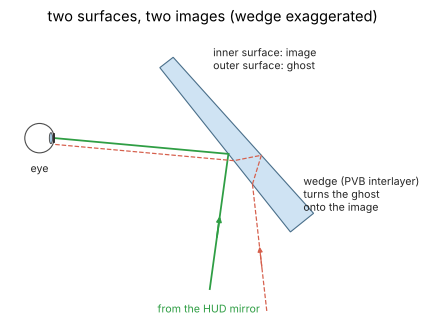

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.6))
with sketch.text_scale(1.2):
    sketch.hud_layout(ax, "double_image", title="two surfaces, two images (wedge exaggerated)")
plt.show()

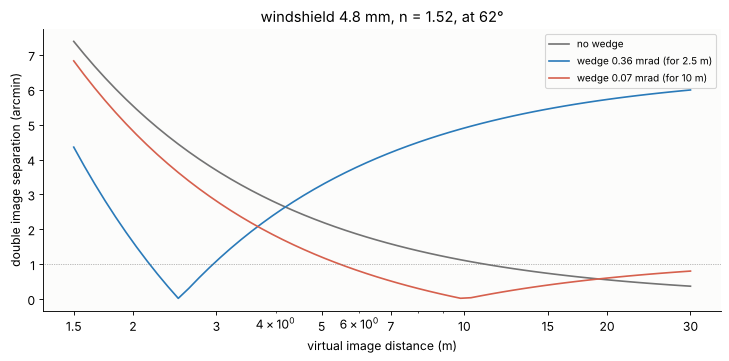

D =   2.5 m: no wedge 4.4', wedge for 2.5 m 0.0', wedge for 10 m 3.6'
D =   7.5 m: no wedge 1.5', wedge for 2.5 m 4.4', wedge for 10 m 0.4'
D =  15.0 m: no wedge 0.7', wedge for 2.5 m 5.4', wedge for 10 m 0.4'
wedge for 2.5 m: 0.360 mrad, i.e. 36 µm thicker per 100 mm of height
transmitted double image of distant lights through the wedge for 2.5 m: about 6.5' (2 n α cos θ_t / cos θ)


In [5]:
T_GLASS = 4.8                                    # mm: two 2.1 mm sheets and a 0.76 mm PVB interlayer
D_list = np.geomspace(1500, 30000, 60)
sep0 = np.array([arvr.windshield_double_image(TH_W, T_GLASS, N_GLASS, 0.0, D) for D in D_list])
w_25 = arvr.wedge_for_distance(TH_W, T_GLASS, N_GLASS, 2500.0)
w_10 = arvr.wedge_for_distance(TH_W, T_GLASS, N_GLASS, 10000.0)
sep_25 = np.array([arvr.windshield_double_image(TH_W, T_GLASS, N_GLASS, w_25, D) for D in D_list])
sep_10 = np.array([arvr.windshield_double_image(TH_W, T_GLASS, N_GLASS, w_10, D) for D in D_list])
fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
ax.semilogx(D_list/1e3, np.abs(sep0)/ARCMIN, color=GREY, label="no wedge")
ax.semilogx(D_list/1e3, np.abs(sep_25)/ARCMIN, color=BLUE, label="wedge {:.2f} mrad (for 2.5 m)".format(abs(w_25)*1e3))
ax.semilogx(D_list/1e3, np.abs(sep_10)/ARCMIN, color=RED, label="wedge {:.2f} mrad (for 10 m)".format(abs(w_10)*1e3))
ax.axhline(1.0, color=GREY, lw=0.6, ls=":")
ax.set_xticks([1.5, 2, 3, 5, 7, 10, 15, 20, 30])
ax.set_xticklabels(["1.5", "2", "3", "5", "7", "10", "15", "20", "30"])
ax.set_xlabel("virtual image distance (m)")
ax.set_ylabel("double image separation (arcmin)")
ax.set_title("windshield {:.1f} mm, n = {:.2f}, at {:.0f}°".format(T_GLASS, N_GLASS, np.degrees(TH_W)))
ax.legend(fontsize=9)
plt.show()
for D in (2500.0, 7500.0, 15000.0):
    print("D = {:5.1f} m: no wedge {:.1f}', wedge for 2.5 m {:.1f}', wedge for 10 m {:.1f}'".format(
        D/1e3, abs(arvr.windshield_double_image(TH_W, T_GLASS, N_GLASS, 0.0, D))/ARCMIN,
        abs(arvr.windshield_double_image(TH_W, T_GLASS, N_GLASS, w_25, D))/ARCMIN,
        abs(arvr.windshield_double_image(TH_W, T_GLASS, N_GLASS, w_10, D))/ARCMIN))
print("wedge for 2.5 m: {:.3f} mrad, i.e. {:.0f} µm thicker per 100 mm of height".format(abs(w_25)*1e3, abs(w_25)*1e5))
# the same wedge seen in transmission: the ghost of the world (two internal reflections)
th_t = np.arcsin(np.sin(TH_W)/N_GLASS)
print("transmitted double image of distant lights through the wedge for 2.5 m: about {:.1f}' "
      "(2 n α cos θ_t / cos θ)".format(2*N_GLASS*abs(w_25)*np.cos(th_t)/np.cos(TH_W)/ARCMIN))

Without a wedge, a 4.8 mm windshield at 62° doubles a HUD image at 2.5 m
by 4.4 arcminutes: clearly visible. The separation falls as $1/D$ (1.5′
at 7.5 m, 0.7′ at 15 m), so it matters most for conventional HUDs. A wedge
of 0.36 mrad, 36 µm of extra thickness per 100 mm of height, removes it
at 2.5 m, but only there: at 7.5 m the same wedge leaves 4.4′, worse than
no wedge, and for an image at infinity it reaches 6.5′. The wedge for 10 m is much smaller (0.07 mrad) and keeps the
separation under 1′ from 7 m on, but leaves 3.6′ at 2.5 m. An AR-HUD that
shows content at several distances cannot be corrected by one wedge;
this is one reason for p-polarized AR-HUDs, whose ghost is weak to begin
with, and for variable-wedge interlayers.

The wedge also acts on the view through the windshield: headlights seen
through it show a faint second image (two internal reflections), shifted by
about $2n\alpha$, here several arcminutes, which is why the wedge is kept
to the HUD zone of the windshield.

## 3. The ray traced HUD

`arvr.hud_system()` builds a HUD with the ray tracer: the display, a
concave HUD mirror (a `raytrace.ZernikeSurface`, so that it can become a
freeform later), the windshield as a mirror (its inner surface, radius 8 m,
concave as seen from the driver), and the plane of the eye box, folded in
the vertical plane. The geometry is that of a compact HUD: display 250 mm
from the mirror, light incident at 20° on the mirror and at 62° on the
windshield, mirror to windshield 400 mm, windshield to eye 900 mm. The
fold mirror of real HUDs is left out; it only packs the path.

What the eye sees follows from `arvr.vergence()`: it aims a ray from a
display point to a point of the eye box (`arvr.aim_ray()`) and traces its
neighbours. The derivative of the arriving slopes with respect to the
position in the eye box is the **vergence matrix**; for light from a point
at the distance $D$ it is $\mathbb 1/D$. Its two eigenvalues are the
inverse image distances in two principal directions (in diopters for
distances in metres); their difference is the **astigmatism**. HUD
specifications ask for something like 0.25 D or less.

The off-axis mirror alone already has two focal lengths, the Coddington
relations

$$f_t = \frac{R\cos\varphi}{2},\qquad f_s = \frac{R}{2\cos\varphi},$$

in and perpendicular to the plane of incidence at the angle $\varphi$.
At 62°, a windshield with a radius of 8 m has $f_t = 1.9$ m and
$f_s = 8.5$ m: a strongly astigmatic weak mirror.

In [6]:
OD = 250.0
VID = 2500.0                                      # target virtual image distance from the eye (mm)
EYES = [(x, y) for x in (-50.0, 0.0, 50.0) for y in (-20.0, 0.0, 20.0)]   # eye box 100 x 40 mm
DISPS = [(x, y) for x in (-45.0, 0.0, 45.0) for y in (-16.0, 0.0, 16.0)]  # display points (mm)


def see(system, eye, disp):
    """Vergence matrix (1/mm) and arrival slope of the light from a display point at an eye point."""
    return arvr.vergence(system, [disp[0], disp[1], -OD], list(eye), [disp[0]/OD, disp[1]/OD, 1.0])


def report(system, label):
    V, _ = see(system, (0.0, 0.0), (0.0, 0.0))
    ev = np.linalg.eigvalsh(0.5*(V + V.T))*1e3
    print("{:28s}: horizontal {:.3f} D ({:.2f} m), vertical {:.3f} D ({:.2f} m), astigmatism {:.3f} D".format(
        label, V[0, 0]*1e3, 1/V[0, 0]/1e3, V[1, 1]*1e3, 1/V[1, 1]/1e3, ev.max() - ev.min()))


report(arvr.hud_system(R_windshield=np.inf), "flat windshield")
report(arvr.hud_system(), "windshield R = 8 m")
# the mirror radius that puts the mean image at 2.5 m
R_grid = np.linspace(-1200, -500, 36)
mean_v = []
for R in R_grid:
    V, _ = see(arvr.hud_system(R_mirror=R), (0.0, 0.0), (0.0, 0.0))
    mean_v.append(0.5*(V[0, 0] + V[1, 1]))
R_sph = np.interp(1/VID, np.array(mean_v)[::-1], R_grid[::-1])
sph = arvr.hud_system(R_mirror=R_sph)
report(sph, "spherical mirror R = {:.0f} mm".format(R_sph))

flat windshield             : horizontal 0.485 D (2.06 m), vertical 0.427 D (2.34 m), astigmatism 0.058 D
windshield R = 8 m          : horizontal 0.446 D (2.24 m), vertical 0.141 D (7.12 m), astigmatism 0.305 D


spherical mirror R = -849 mm: horizontal 0.505 D (1.98 m), vertical 0.296 D (3.38 m), astigmatism 0.209 D


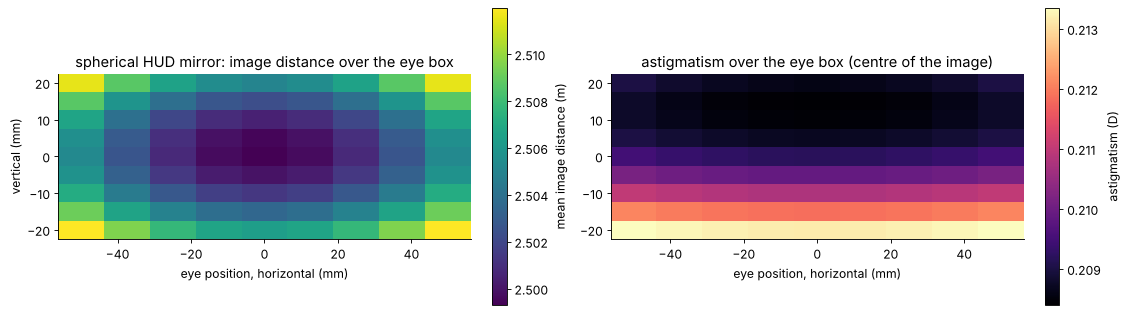

spherical mirror: image distance 2.50 to 2.51 m, astigmatism 0.21 to 0.21 D


In [7]:
def eyebox_maps(system, disp=(0.0, 0.0), n=9):
    xs, ys = np.linspace(-50, 50, n), np.linspace(-20, 20, n)
    vid = np.zeros((n, n))
    ast = np.zeros((n, n))
    for i, y in enumerate(ys):
        for j, x in enumerate(xs):
            V, _ = see(system, (x, y), disp)
            ev = np.linalg.eigvalsh(0.5*(V + V.T))*1e3
            vid[i, j] = 1/ev.mean()
            ast[i, j] = ev.max() - ev.min()
    return xs, ys, vid, ast


xs, ys, vid_s, ast_s = eyebox_maps(sph)
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8), layout="constrained")
im = axs[0].pcolormesh(xs, ys, vid_s, cmap="viridis", shading="auto")
fig.colorbar(im, ax=axs[0], label="mean image distance (m)")
im = axs[1].pcolormesh(xs, ys, ast_s, cmap="magma", shading="auto")
fig.colorbar(im, ax=axs[1], label="astigmatism (D)")
for ax in axs:
    ax.set_xlabel("eye position, horizontal (mm)")
    ax.set_aspect("equal")
axs[0].set_ylabel("vertical (mm)")
axs[0].set_title("spherical HUD mirror: image distance over the eye box")
axs[1].set_title("astigmatism over the eye box (centre of the image)")
plt.show()
print("spherical mirror: image distance {:.2f} to {:.2f} m, astigmatism {:.2f} to {:.2f} D".format(
    vid_s.min(), vid_s.max(), ast_s.min(), ast_s.max()))

A flat windshield and the spherical HUD mirror give an image at about
2.1 to 2.3 m with only 0.06 D of astigmatism: the 20° fold of the mirror
alone is mild. The curved windshield changes this. With a radius of 8 m at
62°, it moves the horizontal (sagittal) focus only a little, from 2.1 to
2.2 m, but pushes the vertical (tangential) one from 2.3 to 7.1 m: 0.3 D of astigmatism, the
Coddington effect of a weak mirror at a steep angle. Adjusting only the
radius of the spherical HUD mirror (849 mm) puts the mean image at 2.5 m,
with 1.98 m horizontally and 3.38 m vertically, 0.21 D apart. The
astigmatism is nearly the same over the whole eye box (0.209 to 0.213 D):
it is a property of the fold, not of the eye position, and a toroidal or
freeform mirror can take it out.

## 4. A freeform HUD mirror

The HUD mirror is the element the designer controls, and it has to undo
what the windshield does. Here it gets Fringe Zernike departures on top of
its base sphere: $Z_5$ (astigmatism at 0°/90°, the toroidal part), $Z_8$
(vertical coma, from the tilted geometry), $Z_9$ (spherical) and $Z_{11}$
($r^4\cos 2\phi$), with the base radius as a further variable. The layout
stays as it is: the folds are those of the base design, so the freeform
only changes the image, not the package. `scipy.optimize.least_squares`
drives the vergence matrices of 6 eye positions (corners and edges of a
100 × 40 mm eye box) and 5 display points (corners and centre) to
$\mathbb 1/2.5\,\text{m}$: equal image distance in both directions and no
astigmatism. Real HUD mirrors are general freeforms (XY polynomials or
NURBS) optimized with many more terms; a handful of Zernikes is enough
to see the effect.

optimized in 13 s: R = -812.7 mm, Z5 = -1.756 mm, Z8 = 0.0402 mm, Z9 = -0.0023 mm, Z11 = 0.0557 mm
worst residual 0.024 D over the optimization points
freeform mirror             : horizontal 0.395 D (2.53 m), vertical 0.397 D (2.52 m), astigmatism 0.002 D


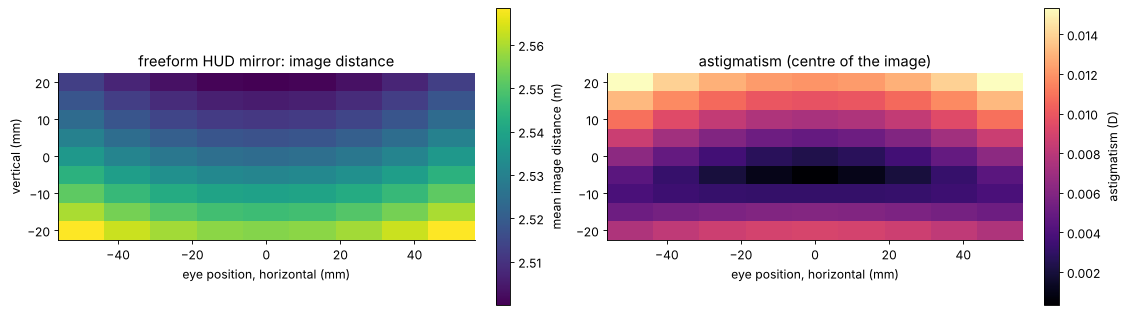

freeform: image distance 2.50 to 2.57 m, astigmatism 0.000 to 0.015 D (centre of the image)


over 9 display points x 9 eye positions: astigmatism max 0.032 D


In [8]:
OPT_EYES = [(x, y) for x in (-50.0, 0.0, 50.0) for y in (-20.0, 20.0)]
OPT_DISPS = [(-45.0, -16.0), (45.0, -16.0), (-45.0, 16.0), (45.0, 16.0), (0.0, 0.0)]


def freeform(p):
    R, z5, z8, z9, z11 = p
    return arvr.hud_system(R_mirror=R, mirror_zernike={5: z5, 8: z8, 9: z9, 11: z11})


def residuals(p):
    s = freeform(p)
    res = []
    try:
        for d in OPT_DISPS:
            for e in OPT_EYES:
                V, _ = see(s, e, d)
                res += [(V[0, 0] - 1/VID)*1e3, (V[1, 1] - 1/VID)*1e3, V[0, 1]*1e3]
    except ValueError:
        return np.full(3*len(OPT_DISPS)*len(OPT_EYES), 10.0)
    return np.array(res)


t0 = time.time()
sol = least_squares(residuals, [R_sph, 0.0, 0.0, 0.0, 0.0], x_scale=[50, 0.1, 0.1, 0.1, 0.1], max_nfev=80)
ff = freeform(sol.x)
print("optimized in {:.0f} s: R = {:.1f} mm, Z5 = {:.3f} mm, Z8 = {:.4f} mm, Z9 = {:.4f} mm, Z11 = {:.4f} mm".format(
    time.time() - t0, *sol.x))
print("worst residual {:.3f} D over the optimization points".format(np.abs(sol.fun).max()))
report(ff, "freeform mirror")
xs, ys, vid_f, ast_f = eyebox_maps(ff)
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8), layout="constrained")
im = axs[0].pcolormesh(xs, ys, vid_f, cmap="viridis", shading="auto")
fig.colorbar(im, ax=axs[0], label="mean image distance (m)")
im = axs[1].pcolormesh(xs, ys, ast_f, cmap="magma", shading="auto")
fig.colorbar(im, ax=axs[1], label="astigmatism (D)")
for ax in axs:
    ax.set_xlabel("eye position, horizontal (mm)")
    ax.set_aspect("equal")
axs[0].set_ylabel("vertical (mm)")
axs[0].set_title("freeform HUD mirror: image distance")
axs[1].set_title("astigmatism (centre of the image)")
plt.show()
print("freeform: image distance {:.2f} to {:.2f} m, astigmatism {:.3f} to {:.3f} D (centre of the image)".format(
    vid_f.min(), vid_f.max(), ast_f.min(), ast_f.max()))
ast_all = [np.ptp(np.linalg.eigvalsh(0.5*(V + V.T)))*1e3 for d in DISPS for e in EYES
           for V in [see(ff, e, d)[0]]]
print("over 9 display points x 9 eye positions: astigmatism max {:.3f} D".format(max(ast_all)))

The optimizer lands on a base radius of 813 mm and a large $Z_5$ term
(−1.76 mm over the 100 mm normalization radius): the mirror becomes
markedly toroidal, with different curvatures in the two planes, which
undoes the windshield's astigmatism. The small coma and $Z_{11}$ terms
handle the variation over the eye box. The result: 2.50 to 2.57 m over the
eye box, astigmatism at most 0.015 D at the centre of the image and at
most 0.03 D over 9 display points and 9 eye positions, more than ten times
inside a 0.25 D specification. The image distance still varies by
0.07 m (0.01 D) from the top to the bottom of the eye box, because the
eye at the bottom sees the image through a different part of the
mirror.

## 5. Two eyes and the eye box

The two eyes, 65 mm apart, look at the same display point through
different parts of the windshield and the mirror. For a comfortable
image they must see it as one point at the image distance: horizontally,
the two lines of sight should converge at $D$ (convergence
$0.065/D$ rad), and vertically they must agree, since the eyes cannot
diverge vertically. The vertical difference, the **dipvergence**, is the
most critical: limits of about one milliradian are typical. Below, for
the freeform design, the convergence error (measured against $0.065/D$)
and the dipvergence for every display point, with the two eyes centred at
three heights in the eye box.

The last plot is the image itself: the directions in which the display's
grid points are seen from the centre and from two corners of the eye
box. The grid is distorted (a smile and a keystone from the off-axis
geometry), which the PGU's software pre-distorts; but the distortion
changes as the head moves (**dynamic distortion**), and the image appears
to swim, which no fixed pre-distortion can remove.

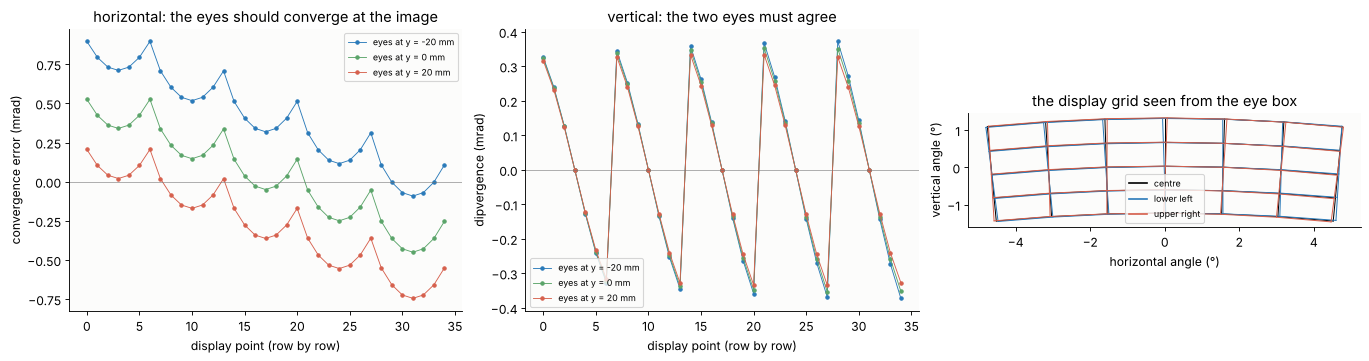

field of view of the 90 x 32 mm display: 9.5° x 2.8°
eyes at y = -20 mm: convergence error up to 0.90 mrad, dipvergence up to 0.37 mrad
eyes at y = +0 mm: convergence error up to 0.53 mrad, dipvergence up to 0.35 mrad
eyes at y = +20 mm: convergence error up to 0.74 mrad, dipvergence up to 0.33 mrad


In [9]:
IPD = 65.0
heights = (-20.0, 0.0, 20.0)
grid = [(x, y) for y in np.linspace(-16, 16, 5) for x in np.linspace(-45, 45, 7)]
conv_err, dipv = {h: [] for h in heights}, {h: [] for h in heights}
for h in heights:
    for d in grid:
        VL, sL = see(ff, (-IPD/2, h), d)
        VR, sR = see(ff, (IPD/2, h), d)
        D_mean = 2/(np.trace(0.5*(VL + VR)))                       # image distance (mm)
        # slopes point along the light (into the eye); the line of sight is opposite
        conv = sR[0] - sL[0]                                      # convergence of the two sight lines
        conv_err[h].append(conv - IPD/D_mean)
        dipv[h].append(sL[1] - sR[1])
fig, axs = plt.subplots(1, 3, figsize=(17, 4.4), layout="constrained")
gx = np.array([g[0] for g in grid])
gy = np.array([g[1] for g in grid])
for h, c in zip(heights, (BLUE, GREEN, RED)):
    axs[0].plot(1e3*np.array(conv_err[h]), "o-", color=c, ms=3, lw=0.8, label="eyes at y = {:.0f} mm".format(h))
    axs[1].plot(1e3*np.array(dipv[h]), "o-", color=c, ms=3, lw=0.8, label="eyes at y = {:.0f} mm".format(h))
for ax, t in zip(axs[:2], ("convergence error (mrad)", "dipvergence (mrad)")):
    ax.set_xlabel("display point (row by row)")
    ax.set_ylabel(t)
    ax.axhline(0, color=GREY, lw=0.5)
    ax.legend(fontsize=8)
axs[0].set_title("horizontal: the eyes should converge at the image")
axs[1].set_title("vertical: the two eyes must agree")
# distortion seen from three eye positions
dense = [(x, y) for y in np.linspace(-16, 16, 5) for x in np.linspace(-45, 45, 7)]
for e, c, lab in (((0.0, 0.0), "k", "centre"), ((-50.0, -20.0), BLUE, "lower left"), ((50.0, 20.0), RED, "upper right")):
    S = np.array([see(ff, e, d)[1] for d in dense])
    ang_x = -np.degrees(S[:, 0]) + np.degrees(e[0]/VID)        # remove the parallax of the eye position
    ang_y = -np.degrees(S[:, 1]) + np.degrees(e[1]/VID)
    ang_x, ang_y = ang_x.reshape(5, 7), ang_y.reshape(5, 7)
    for r in range(5):
        axs[2].plot(ang_x[r], ang_y[r], color=c, lw=0.9)
    for q in range(7):
        axs[2].plot(ang_x[:, q], ang_y[:, q], color=c, lw=0.9)
    axs[2].plot([], [], color=c, label=lab)
axs[2].set_xlabel("horizontal angle (°)")
axs[2].set_ylabel("vertical angle (°)")
axs[2].set_title("the display grid seen from the eye box")
axs[2].legend(fontsize=8)
axs[2].set_aspect("equal")
plt.show()
S0 = np.array([see(ff, (0.0, 0.0), d)[1] for d in dense])
fov_h = np.degrees(np.ptp(S0[:, 0]))
fov_v = np.degrees(np.ptp(S0[:, 1]))
print("field of view of the 90 x 32 mm display: {:.1f}° x {:.1f}°".format(fov_h, fov_v))
for h in heights:
    print("eyes at y = {:+.0f} mm: convergence error up to {:.2f} mrad, dipvergence up to {:.2f} mrad".format(
        h, 1e3*np.max(np.abs(conv_err[h])), 1e3*np.max(np.abs(dipv[h]))))

The 90 × 32 mm display fills a 9.5° × 2.8° field of view, about the
size of a conventional HUD. The two eyes converge on the image to within
0.5 to 0.9 mrad of the convergence of a point at 2.5 m, and their
vertical directions differ by at most 0.37 mrad: well inside a 1 mrad
dipvergence limit. The dipvergence varies systematically across each row
of the image, a twist that a design with more freeform terms (and with a
specification on it) would reduce.

The grid seen from the centre and from two corners of the eye box is
slightly curved (a smile of the off-axis geometry) and nearly the same
from all three points: the dynamic distortion of this design is small,
and a fixed pre-distortion of the display would straighten the image for
any head position. Real windshields, which are not spheres and vary
from car to car, make this much harder; HUDs are often calibrated per
car model, and AR-HUDs track the driver's eyes to adapt the
pre-distortion.

## Summary

- The windshield is a mirror at 60° to 65°, near Brewster's angle: it
  reflects s light by about 20 % and p light hardly at all. Polarized
  sunglasses block s; p-HUDs need a coating.
- Its two surfaces make a double image, a few arcminutes at 2.5 m; a
  wedged interlayer of a fraction of a milliradian removes it for one
  image distance only, which is a problem for AR-HUDs at 10 m and more.
- The off-axis geometry and the curved windshield make the image strongly
  astigmatic. A freeform HUD mirror corrects the image distance and the
  astigmatism over the eye box; the remaining disparity between the eyes
  and the distortion that changes with the head position are what HUD
  designs are judged by.

## References

- J. Wood, "Head-up displays", in: *Handbook of Visual Display
  Technology*, Springer (2012).
- Z. Qin, F.-C. Lin, Y.-P. Huang and H.-P. D. Shieh, "Maximal acceptable
  ghost images for designing a legible windshield-type vehicle head-up
  display", IEEE Photonics J. 9, 7000812 (2017).
- K.-H. Kim and S.-C. Park, "Optical system design and evaluation of a
  head-up display with a freeform mirror", Curr. Opt. Photonics 5, 1–8
  (2021).
- J. P. Rolland and H. Hua, "Head-mounted display systems", in:
  *Encyclopedia of Optical Engineering*, Marcel Dekker (2005).
- B. C. Kress, *Optical Architectures for Augmented-, Virtual-, and
  Mixed-Reality Headsets*, SPIE Press (2020).

In [10]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 19 s
